<a href="https://colab.research.google.com/github/YashVardhanSingh216/Deep-Learning/blob/main/12_HandwrittenDigitClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# MNIST DATASET
import tensorflow
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten

In [2]:
(x_train,y_train),(x_test,y_test)=mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
x_train.shape

(60000, 28, 28)

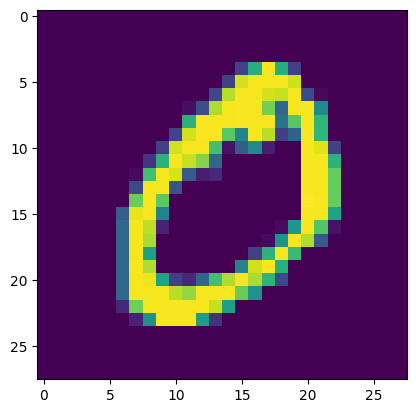

In [5]:
import matplotlib.pyplot as plt
plt.imshow(x_train[1])

In [6]:
x_train = x_train/255
x_test = x_test/255

In [31]:
model = Sequential()

model.add(Flatten(input_shape=(28,28)))
model.add(Dense(128,activation='relu'))
model.add(Dense(32,activation='relu'))
model.add(Dense(10,activation='softmax'))

In [32]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
model.compile(loss = 'sparse_categorical_crossentropy', optimizer = 'Adam', metrics=['accuracy'])

In [38]:
history = model.fit(x_train,y_train,epochs=25, validation_split=0.2)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9158 - loss: 0.2869 - val_accuracy: 0.9551 - val_loss: 0.1471
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9643 - loss: 0.1215 - val_accuracy: 0.9636 - val_loss: 0.1212
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9738 - loss: 0.0856 - val_accuracy: 0.9671 - val_loss: 0.1118
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9801 - loss: 0.0636 - val_accuracy: 0.9703 - val_loss: 0.0990
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9845 - loss: 0.0489 - val_accuracy: 0.9693 - val_loss: 0.0991
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9876 - loss: 0.0396 - val_accuracy: 0.9727 - val_loss: 0.1058
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9897 - loss: 0.0325 - val_accuracy: 0.9749 - val_loss: 0.0955
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9916 - loss: 0.0259 - 

In [39]:
y_prob = model.predict(x_test)
y_prob

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[7.4206179e-12, 2.5006734e-17, 4.9831813e-13, ..., 9.9999994e-01,
        4.1607240e-16, 6.7317145e-11],
       [3.0123495e-26, 6.0036139e-16, 9.9999994e-01, ..., 8.4233711e-26,
        9.9521532e-18, 1.6238748e-27],
       [7.3384814e-14, 9.9999982e-01, 8.7803770e-08, ..., 1.3395518e-08,
        5.1643756e-08, 1.5425688e-14],
       ...,
       [3.0005056e-24, 1.6464635e-24, 1.2174354e-23, ..., 2.0097460e-17,
        1.5354118e-15, 8.7831137e-14],
       [5.4392275e-24, 1.4722396e-20, 5.9074667e-25, ..., 6.3648595e-22,
        4.9628926e-13, 4.5334590e-24],
       [4.0325613e-22, 2.5938585e-25, 1.3843955e-23, ..., 6.1685340e-31,
        6.3461089e-25, 1.7870011e-24]], dtype=float32)

In [40]:
y_pred = y_prob.argmax(axis = 1)

In [41]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.9772

Text(0.5, 0, 'Epochs')

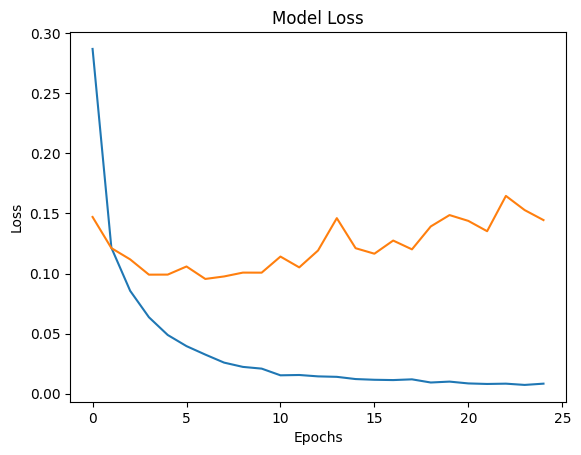

In [42]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epochs')

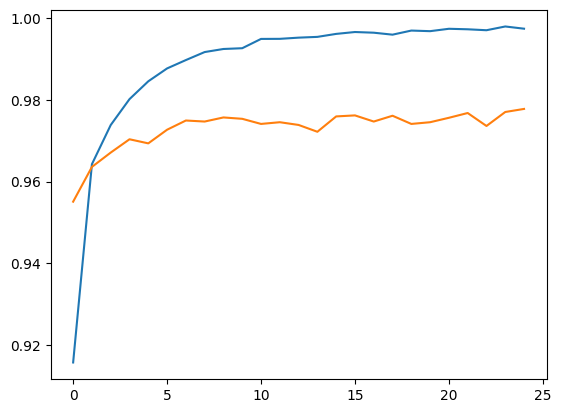

In [43]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

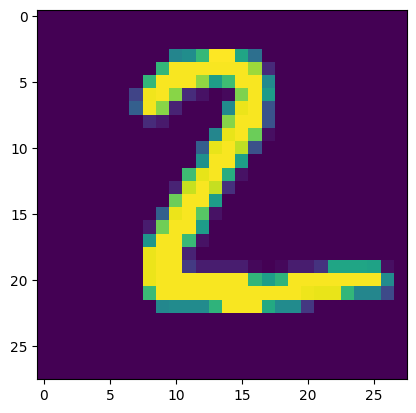

In [47]:
plt.imshow(x_test[1])

In [48]:
model.predict(x_test[1].reshape(1,28,28)).argmax(axis = 1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


array([2])